In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data"

columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

df = pd.read_csv(url, names=columns)


In [3]:
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Shape: (1728, 7)

Columns:
['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [5]:
df.isnull().sum()


buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

In [6]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["class_encoded"] = label_encoder.fit_transform(df["class"])

df[["class", "class_encoded"]].head(10)

,class,class_encoded
0,unacc,2
1,unacc,2
2,unacc,2
3,unacc,2
4,unacc,2
5,unacc,2
6,unacc,2
7,unacc,2
8,unacc,2
9,unacc,2


In [7]:
# Step 6: Encode the input features

feature_columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety"
]

X = pd.get_dummies(df[feature_columns], dtype=int)
y = df["class_encoded"]

X.head()

,buying_high,buying_low,buying_med,buying_vhigh,maint_high,maint_low,maint_med,maint_vhigh,doors_2,doors_3,...,doors_5more,persons_2,persons_4,persons_more,lug_boot_big,lug_boot_med,lug_boot_small,safety_high,safety_low,safety_med
0,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,0,1,0
1,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,0,0,1
2,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,1,0,0
3,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,1,0
4,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,0,1


In [8]:
# Step 7: Split the data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1382, 21)
Testing features: (346, 21)
Training target: (1382,)
Testing target: (346,)


In [9]:
# Step 8: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (1382, 21)
Scaled testing data shape: (346, 21)


In [10]:
# Step 9: Train the KNN Classifier

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=21)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("KNN predictions completed successfully.")

KNN predictions completed successfully.


In [11]:
# Step 10: Evaluate KNN Accuracy

from sklearn.metrics import accuracy_score

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)
print("KNN Accuracy (%):", round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 0.8063583815028902
KNN Accuracy (%): 80.64 %


Confusion Matrix:
[[ 38   0  45   0]
 [  1   6   4   0]
 [  0   0 235   0]
 [  5   2  10   0]]


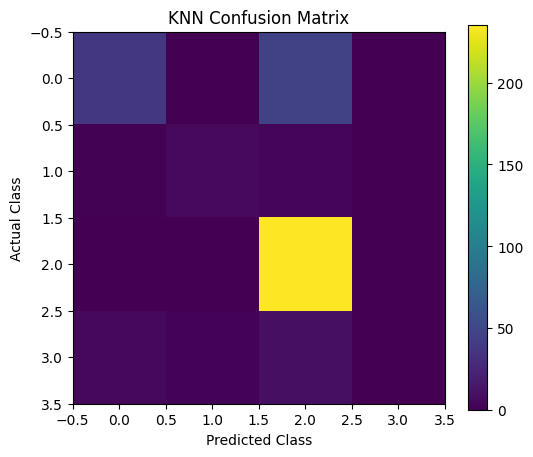

In [12]:
# Step 11: KNN Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_knn)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.colorbar()
plt.show()

In [13]:
# Step 12: KNN Classification Report (k=21)

from sklearn.metrics import classification_report

print("KNN Classification Report (k=21):")
print(classification_report(
    y_test,
    y_pred_knn,
    zero_division=0
))

KNN Classification Report (k=21):
              precision    recall  f1-score   support

           0       0.86      0.46      0.60        83
           1       0.75      0.55      0.63        11
           2       0.80      1.00      0.89       235
           3       0.00      0.00      0.00        17

    accuracy                           0.81       346
   macro avg       0.60      0.50      0.53       346
weighted avg       0.77      0.81      0.77       346



In [14]:
# Step 13: Train the Logistic Regression Model

from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)

log_reg.fit(X_train_scaled, y_train)

y_pred_log = log_reg.predict(X_test_scaled)

print("Logistic Regression predictions completed successfully.")

Logistic Regression predictions completed successfully.


In [15]:
# Step 14: Evaluate Logistic Regression Accuracy

from sklearn.metrics import accuracy_score, classification_report

log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", round(log_accuracy * 100, 2), "%")

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred_log,
    zero_division=0
))

Logistic Regression Accuracy: 92.77 %

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.81      0.85        83
           1       0.59      0.91      0.71        11
           2       0.96      0.97      0.97       235
           3       0.94      0.94      0.94        17

    accuracy                           0.93       346
   macro avg       0.85      0.91      0.87       346
weighted avg       0.93      0.93      0.93       346



Logistic Regression Confusion Matrix:
[[ 67   7   9   0]
 [  0  10   0   1]
 [  7   0 228   0]
 [  1   0   0  16]]


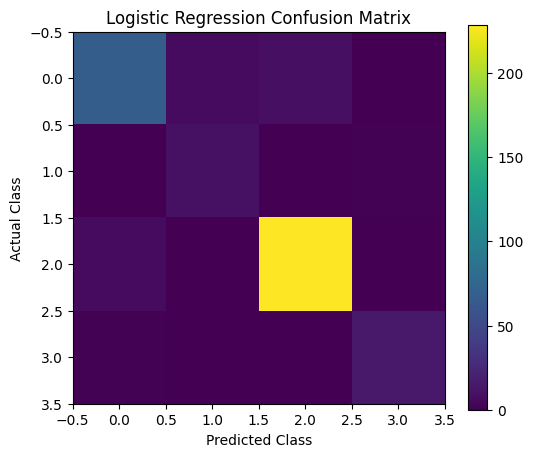

In [16]:
# Step 15: Logistic Regression Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm_log = confusion_matrix(y_test, y_pred_log)

print("Logistic Regression Confusion Matrix:")
print(cm_log)

plt.figure(figsize=(6, 5))
plt.imshow(cm_log)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.colorbar()
plt.show()

In [17]:
# Step 16: Logistic Regression ROC-AUC

from sklearn.metrics import roc_auc_score

y_proba_log = log_reg.predict_proba(X_test_scaled)

log_roc_auc = roc_auc_score(
    y_test,
    y_proba_log,
    multi_class="ovr",
    average="weighted"
)

print("Logistic Regression ROC-AUC:", round(log_roc_auc, 4))

Logistic Regression ROC-AUC: 0.9917


In [18]:
# Step 17: KNN ROC-AUC

knn_proba = knn.predict_proba(X_test_scaled)

knn_roc_auc = roc_auc_score(
    y_test,
    knn_proba,
    multi_class="ovr",
    average="weighted"
)

print("KNN ROC-AUC:", round(knn_roc_auc, 4))

KNN ROC-AUC: 0.9812


In [19]:
# Step 18: Model Comparison Table

comparison = pd.DataFrame({
    "Model": ["KNN (k=21)", "Logistic Regression"],
    "Accuracy (%)": [
        round(knn_accuracy * 100, 2),
        round(log_accuracy * 100, 2)
    ],
    "ROC-AUC": [
        round(knn_roc_auc, 4),
        round(log_roc_auc, 4)
    ]
})

comparison = comparison.set_index("Model")

comparison

,Accuracy (%),ROC-AUC
Model,,
KNN (k=21),80.64,0.9812
Logistic Regression,92.77,0.9917


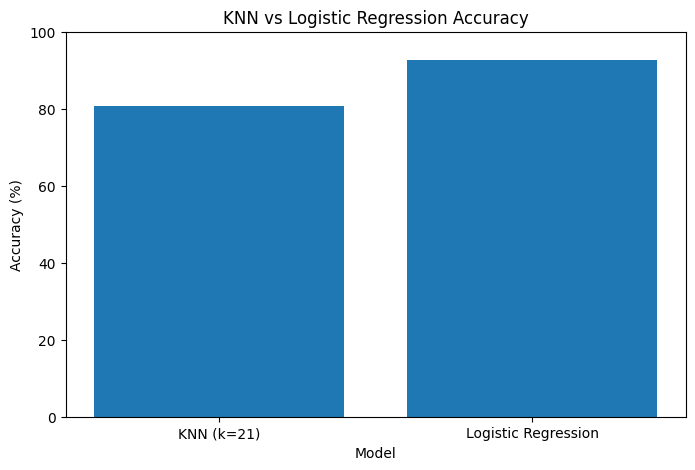

In [20]:
# Step 19: Model Comparison Visualization

import matplotlib.pyplot as plt

models = ["KNN (k=21)", "Logistic Regression"]
accuracies = [knn_accuracy * 100, log_accuracy * 100]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)

plt.title("KNN vs Logistic Regression Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

In [21]:
# Step 20: Model Comparison Analysis

print("MODEL COMPARISON")
print("-" * 40)

print(f"KNN (k=21) Accuracy: {knn_accuracy * 100:.2f}%")
print(f"KNN (k=21) ROC-AUC: {knn_roc_auc:.4f}")

print(f"\nLogistic Regression Accuracy: {log_accuracy * 100:.2f}%")
print(f"Logistic Regression ROC-AUC: {log_roc_auc:.4f}")

print("\nConclusion:")
if log_accuracy > knn_accuracy:
    print("Logistic Regression performed better than KNN based on accuracy.")
else:
    print("KNN performed better than Logistic Regression based on accuracy.")

MODEL COMPARISON
----------------------------------------
KNN (k=21) Accuracy: 80.64%
KNN (k=21) ROC-AUC: 0.9812

Logistic Regression Accuracy: 92.77%
Logistic Regression ROC-AUC: 0.9917

Conclusion:
Logistic Regression performed better than KNN based on accuracy.
